# AI-Based Cardiovascular Disease Prediction
## Comparative Machine Learning and Neural Network Classification

**Models compared:** Decision Tree · Naive Bayes · K-Nearest Neighbour · Artificial Neural Network (MLP)
**Dataset:** `cardio_train.csv` (70,000 patient records, 11 clinical/lifestyle features, binary target `cardio`)

**Notebook roadmap (maps to the 8 project objectives)**

| # | Section | Objective |
|---|---|---|
| 1 | Data loading & overview | 1 |
| 2 | Cleaning, encoding, feature engineering | 2 |
| 3 | Exploratory analysis & risk factors | 1 |
| 4 | Train/test split & scaling pipeline | 2, 4 |
| 5 | Model development with hyper-parameter tuning + 5-fold CV | 3, 4 |
| 6 | Test-set evaluation (Accuracy, Precision, Recall, F1, Confusion Matrix, ROC) | 5 |
| 7 | Feature importance & interpretation | 6 |
| 8 | Strengths / weaknesses / limitations | 7 |
| 9 | Conceptual intelligent healthcare prediction system | 8 |


In [1]:
import warnings, time, joblib
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
DATA_PATH = 'data/cardio_train.csv'   # change if the file is elsewhere

## 1. Data loading & overview

In [2]:
raw = pd.read_csv(DATA_PATH, sep=';')
print('Shape:', raw.shape)
display(raw.head())
display(raw.describe().T.round(2))
print('Missing values:', int(raw.isna().sum().sum()))
print('Duplicate rows (ignoring id):', int(raw.drop(columns='id').duplicated().sum()))
print('\nTarget balance:'); print(raw['cardio'].value_counts(normalize=True).round(3))

Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.42,28851.30,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.87,2467.25,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.35,0.48,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.36,8.21,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.21,14.40,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.82,154.01,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.63,188.47,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.37,0.68,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.23,0.57,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.09,0.28,0.0,0.00,0.0,0.00,1.0


Missing values: 0
Duplicate rows (ignoring id): 24

Target balance:
cardio
0    0.5
1    0.5
Name: proportion, dtype: float64


**Data dictionary**

| Feature | Meaning | Type |
|---|---|---|
| age | Age in **days** (converted to years below) | numeric |
| gender | 1 = female, 2 = male | binary |
| height (cm), weight (kg) | Body measurements | numeric |
| ap_hi / ap_lo | Systolic / diastolic blood pressure | numeric |
| cholesterol | 1 normal, 2 above normal, 3 well above normal | ordinal |
| gluc | Glucose: 1 normal, 2 above normal, 3 well above normal | ordinal |
| smoke, alco, active | Smoking, alcohol intake, physical activity | binary |
| **cardio** | **Target:** presence (1) / absence (0) of cardiovascular disease | binary |


**Observations.** The dataset has 70,000 rows, no missing values, only 24 exact duplicates, and a perfectly balanced target (50.0 % / 50.0 %), so accuracy is a fair headline metric here. However, `describe()` exposes serious data-quality problems: systolic BP ranges from −150 to 16,020 mmHg, diastolic BP from −70 to 11,000 mmHg, height from 55 cm and weight from 10 kg. These are entry errors and must be handled before modelling.

## 2. Data cleaning, encoding and feature engineering
Steps: (a) drop `id` and exact duplicates, (b) convert age to years, (c) remove physiologically impossible values (the raw data contains systolic BP up to 16,020 mmHg and heights of 55 cm), (d) engineer BMI and pulse pressure, (e) encode categorical variables.

In [3]:
df = raw.drop(columns='id').drop_duplicates().copy()
n0 = len(df)

df['age_years'] = (df['age'] / 365.25).round(1)
df = df.drop(columns='age')

# --- Outlier / impossible-value rules (documented clinical plausibility ranges) ---
rules = {
    'height 120-220 cm'        : df['height'].between(120, 220),
    'weight 30-200 kg'         : df['weight'].between(30, 200),
    'systolic 70-250 mmHg'     : df['ap_hi'].between(70, 250),
    'diastolic 40-150 mmHg'    : df['ap_lo'].between(40, 150),
    'systolic > diastolic'     : df['ap_hi'] > df['ap_lo'],
}
for name, ok in rules.items():
    print(f'{name:<26} -> violating rows: {(~ok).sum():>5}')
mask = np.logical_and.reduce(list(rules.values()))
df = df[mask].copy()
print(f'\nRows before: {n0:,}  after cleaning: {len(df):,}  (removed {n0-len(df):,} = {100*(n0-len(df))/n0:.2f}%)')

# --- Feature engineering ---
df['bmi'] = (df['weight'] / (df['height']/100)**2).round(2)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']
df = df[df['bmi'].between(12, 60)].copy()

# --- Encoding ---
df['gender'] = (df['gender'] == 2).astype(int)      # 0 = female, 1 = male
# cholesterol & gluc are ORDINAL (1<2<3) -> kept as ordered integers (one-hot would discard the order)
df = df.reset_index(drop=True)
print('Final shape:', df.shape)
display(df.head())

height 120-220 cm          -> violating rows:    53
weight 30-200 kg           -> violating rows:     7
systolic 70-250 mmHg       -> violating rows:   229
diastolic 40-150 mmHg      -> violating rows:  1034
systolic > diastolic       -> violating rows:  1236

Rows before: 69,976  after cleaning: 68,586  (removed 1,390 = 1.99%)
Final shape: (68561, 14)


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,pulse_pressure
0,1,168,62.0,110,80,1,1,0,0,1,0,50.4,21.97,30
1,0,156,85.0,140,90,3,1,0,0,1,1,55.4,34.93,50
2,0,165,64.0,130,70,3,1,0,0,0,1,51.6,23.51,60
3,1,169,82.0,150,100,1,1,0,0,1,1,48.2,28.71,50
4,0,156,56.0,100,60,1,1,0,0,0,0,47.8,23.01,40


**Cleaning outcome.** 1,390 rows (≈2 %) violated at least one plausibility rule (the biggest groups were *systolic ≤ diastolic* with 1,236 rows and implausible diastolic values with 1,034 rows; the rules overlap), plus 24 duplicates and 25 extreme-BMI rows. **68,561 of 70,000 records (97.9 %) are retained.** Age was converted from days to years, BMI and pulse pressure were engineered, gender was encoded 0/1, and cholesterol/glucose were kept as ordered integers because their categories are naturally ranked.

## 3. Exploratory analysis & cardiovascular risk factors

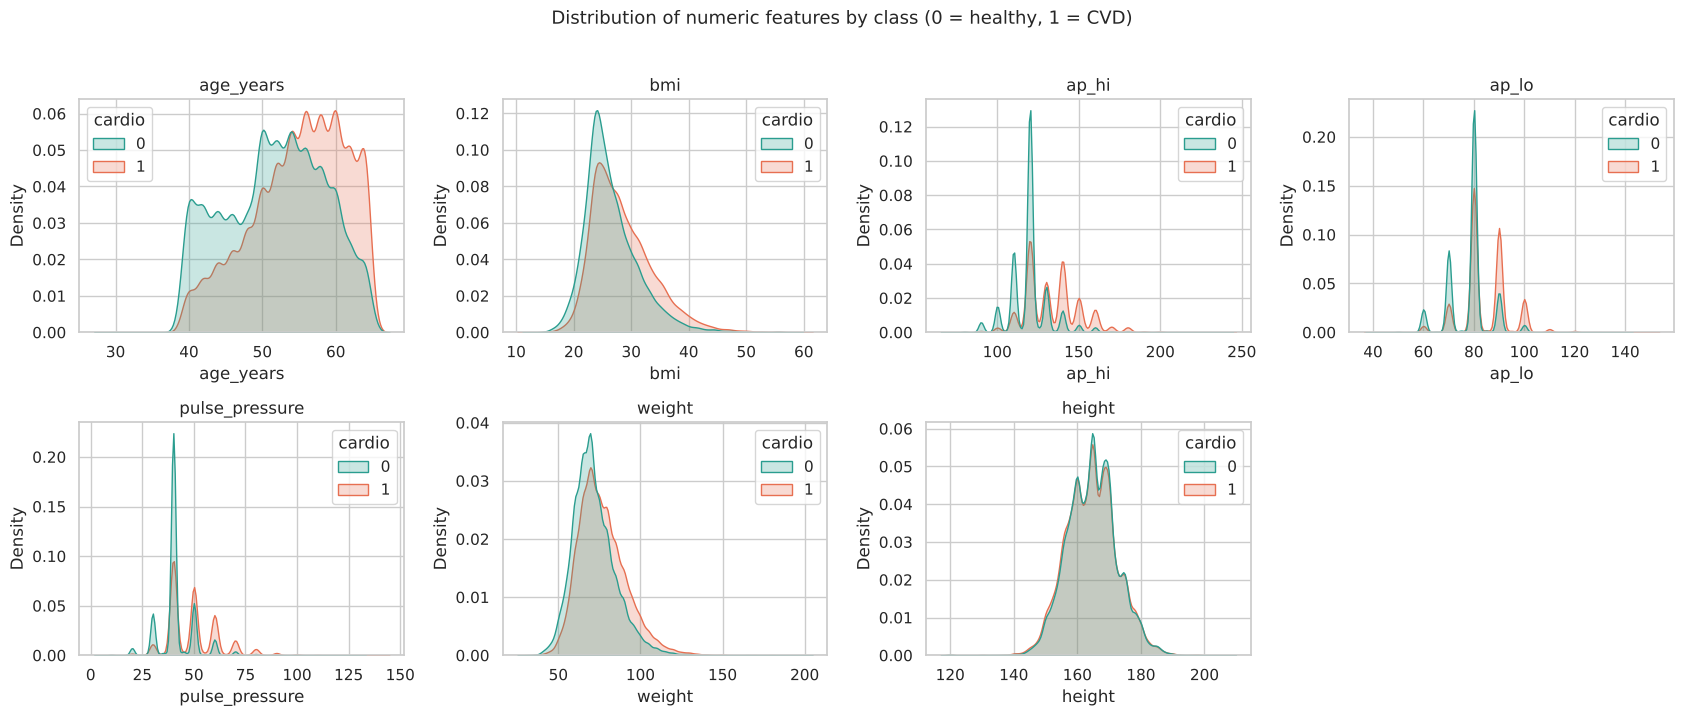

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), ['age_years','bmi','ap_hi','ap_lo','pulse_pressure','weight','height']):
    sns.kdeplot(data=df, x=col, hue='cardio', fill=True, common_norm=False, ax=ax, palette=['#2a9d8f','#e76f51'])
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.suptitle('Distribution of numeric features by class (0 = healthy, 1 = CVD)', y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

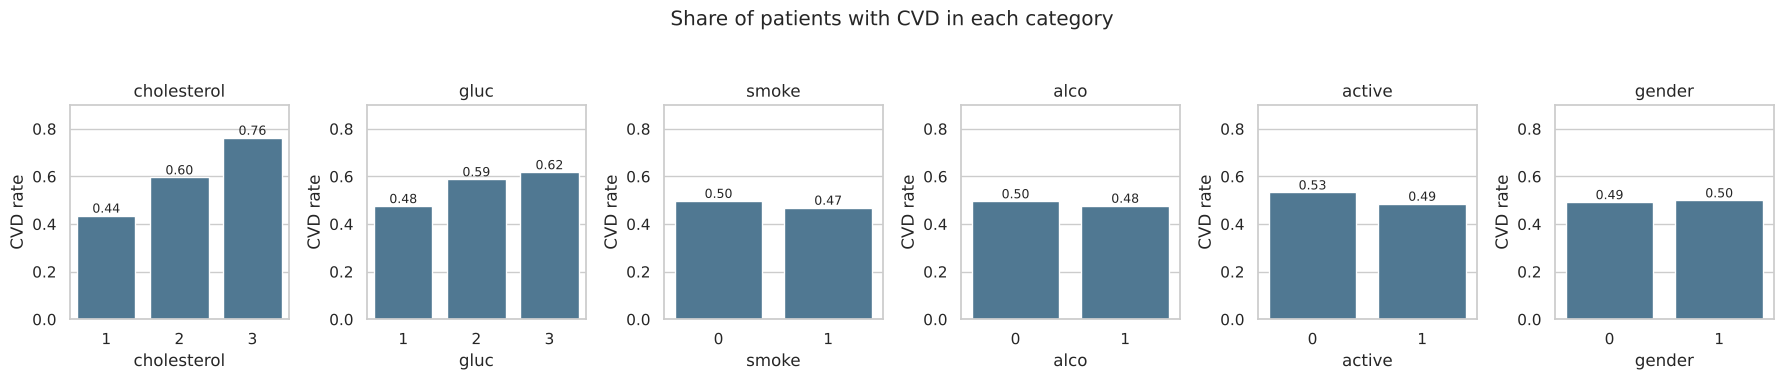

In [5]:
cats = ['cholesterol','gluc','smoke','alco','active','gender']
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, c in zip(axes, cats):
    rate = df.groupby(c)['cardio'].mean()
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='#457b9d')
    ax.set_title(c); ax.set_ylabel('CVD rate'); ax.set_ylim(0, 0.9)
    for p in ax.patches: ax.annotate(f'{p.get_height():.2f}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.suptitle('Share of patients with CVD in each category', y=1.05); plt.tight_layout(); plt.show()

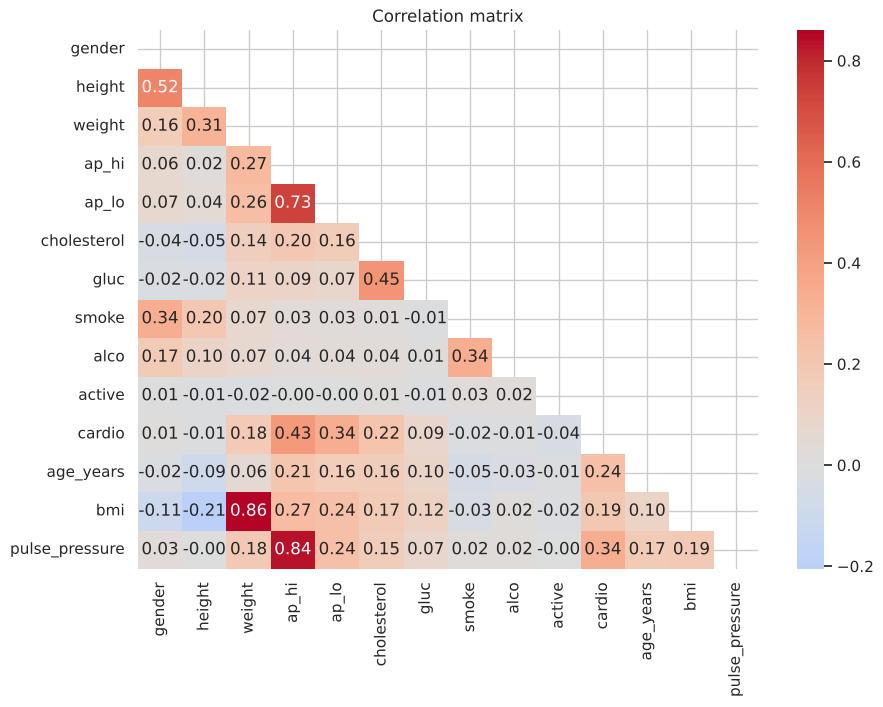

Correlation with target:
ap_hi             0.428
ap_lo             0.341
pulse_pressure    0.337
age_years         0.240
cholesterol       0.221
bmi               0.191
weight            0.181
gluc              0.090
gender            0.007
alco             -0.008
height           -0.012
smoke            -0.016
active           -0.038
Name: cardio, dtype: float64


In [6]:
plt.figure(figsize=(10, 7))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title('Correlation matrix'); plt.show()
print('Correlation with target:'); print(corr['cardio'].drop('cardio').sort_values(ascending=False).round(3))

**Risk-factor findings (correlation with the target).** Blood-pressure variables dominate: systolic BP (r = 0.43), diastolic BP (0.34) and pulse pressure (0.34). Then age (0.24), cholesterol (0.22), BMI (0.19) and weight (0.18), with glucose weaker (0.09). Gender, height, smoking, alcohol and activity are all near zero (|r| ≤ 0.04). The slightly *negative* correlation for smoking and activity is counter-intuitive and probably reflects self-reported, noisy lifestyle data rather than a protective effect. Systolic and diastolic BP are strongly inter-correlated, which matters for Naive Bayes (independence assumption) and for interpreting importance scores.

## 4. Train / test split and preprocessing pipeline
* **80 / 20 stratified split** (class balance preserved). The test set is touched **only once**, at the end.
* `StandardScaler` is placed **inside** each `Pipeline`, so it is fitted on training folds only – this prevents data leakage during cross-validation. It is essential for KNN (distance-based) and the ANN (gradient-based), and harmless for tree/Naive Bayes.

In [7]:
FEATURES = ['age_years','gender','height','weight','bmi','ap_hi','ap_lo','pulse_pressure','cholesterol','gluc','smoke','alco','active']
X, y = df[FEATURES], df['cardio']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}  Test: {X_test.shape}')
print('Train class balance:', y_train.mean().round(3), '| Test:', y_test.mean().round(3))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (54848, 13)  Test: (13713, 13)
Train class balance: 0.495 | Test: 0.495


## 5. Model development, hyper-parameter tuning and cross-validation
Each model is tuned with `GridSearchCV` (5-fold stratified CV on the **training set**, optimising F1). Grids are intentionally compact so the notebook runs in a few minutes on a laptop.

In [8]:
models = {
 'Decision Tree': (Pipeline([('sc', StandardScaler()), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {'clf__max_depth':[3,5,7,10], 'clf__min_samples_leaf':[20,50,100], 'clf__criterion':['gini','entropy']}),
 'Naive Bayes':   (Pipeline([('sc', StandardScaler()), ('clf', GaussianNB())]),
    {'clf__var_smoothing':[1e-9,1e-7,1e-5,1e-3]}),
 'KNN':           (Pipeline([('sc', StandardScaler()), ('clf', KNeighborsClassifier(n_jobs=-1))]),
    {'clf__n_neighbors':[15,31,51,75], 'clf__weights':['uniform','distance']}),
 'ANN (MLP)':     (Pipeline([('sc', StandardScaler()), ('clf', MLPClassifier(early_stopping=True, validation_fraction=0.1,
                                n_iter_no_change=10, max_iter=300, random_state=RANDOM_STATE))]),
    {'clf__hidden_layer_sizes':[(32,),(64,32)], 'clf__alpha':[1e-4,1e-2], 'clf__learning_rate_init':[1e-3]}),
}
best, tuning = {}, []
for name, (pipe, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1', n_jobs=1, refit=True)
    gs.fit(X_train, y_train)
    best[name] = gs.best_estimator_
    tuning.append({'Model':name, 'Best params':{k.replace('clf__',''):v for k,v in gs.best_params_.items()},
                   'CV F1 (tuned)':round(gs.best_score_,4), 'Search time (s)':round(time.time()-t0,1)})
    print(f'{name:<14} done in {time.time()-t0:5.1f}s | best CV F1 = {gs.best_score_:.4f} | {gs.best_params_}')
display(pd.DataFrame(tuning))

Decision Tree  done in  11.7s | best CV F1 = 0.7156 | {'clf__criterion': 'gini', 'clf__max_depth': 7, 'clf__min_samples_leaf': 50}


Naive Bayes    done in   0.6s | best CV F1 = 0.6796 | {'clf__var_smoothing': 1e-09}


KNN            done in 154.9s | best CV F1 = 0.7133 | {'clf__n_neighbors': 31, 'clf__weights': 'uniform'}


ANN (MLP)      done in  54.1s | best CV F1 = 0.7214 | {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.001}


,Model,Best params,CV F1 (tuned),Search time (s)
0,Decision Tree,"{'criterion': 'gini', 'max_depth': 7, 'min_sam...",0.7156,11.7
1,Naive Bayes,{'var_smoothing': 1e-09},0.6796,0.6
2,KNN,"{'n_neighbors': 31, 'weights': 'uniform'}",0.7133,154.9
3,ANN (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32)...",0.7214,54.1


In [9]:
# 5-fold cross-validation of the tuned models on all four metrics (mean ± std)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
rows = []
for name, est in best.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({'Model':name, **{m: f"{r['test_'+m].mean():.4f} ± {r['test_'+m].std():.4f}" for m in scoring}})
cv_table = pd.DataFrame(rows).set_index('Model'); display(cv_table)

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Decision Tree,0.7303 ± 0.0030,0.7480 ± 0.0061,0.6860 ± 0.0055,0.7156 ± 0.0027,0.7933 ± 0.0040
Naive Bayes,0.7149 ± 0.0043,0.7655 ± 0.0064,0.6110 ± 0.0040,0.6796 ± 0.0045,0.7796 ± 0.0043
KNN,0.7285 ± 0.0026,0.7469 ± 0.0046,0.6827 ± 0.0021,0.7133 ± 0.0019,0.7879 ± 0.0036
ANN (MLP),0.7331 ± 0.0018,0.7460 ± 0.0045,0.6984 ± 0.0057,0.7214 ± 0.0020,0.7986 ± 0.0040


**Reading the cross-validation table (5-fold, training data only).** ANN has the best CV F1 (0.7214 ± 0.0020), followed by Decision Tree (0.7156), KNN (0.7133) and Naive Bayes (0.6796). ROC-AUC shows the same order, with ANN and Decision Tree close (0.799 vs 0.793). The gaps among the top three are small (about 0.5–1 F1 points, only 1–3 standard deviations), so they are *consistent but modest* differences; Naive Bayes is clearly the weakest, mainly because of low recall (0.611). A shallow tree (depth 7, ≥ 50 samples per leaf) was best, showing that heavier trees overfit this noisy data.

## 6. Final evaluation on the held-out test set

In [10]:
results, preds, probas, timing = [], {}, {}, {}
for name, est in best.items():
    t0=time.time(); est.fit(X_train, y_train); tr=time.time()-t0
    t0=time.time(); p = est.predict(X_test); pr=time.time()-t0
    preds[name]=p; probas[name]=est.predict_proba(X_test)[:,1]; timing[name]=(tr,pr)
    results.append({'Model':name,'Accuracy':accuracy_score(y_test,p),'Precision':precision_score(y_test,p),
                    'Recall':recall_score(y_test,p),'F1-Score':f1_score(y_test,p),'ROC-AUC':roc_auc_score(y_test,probas[name]),
                    'Train time (s)':tr,'Predict time (s)':pr})
res = pd.DataFrame(results).set_index('Model').round(4)
display(res.style.background_gradient(cmap='Greens', subset=['Accuracy','Precision','Recall','F1-Score','ROC-AUC']).format('{:.4f}'))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train time (s),Predict time (s)
Model,,,,,,,
Decision Tree,0.7308,0.7538,0.6770,0.7134,0.7965,0.1379,0.0048
Naive Bayes,0.7120,0.7621,0.6076,0.6761,0.7786,0.0276,0.0041
KNN,0.7243,0.7420,0.6788,0.7090,0.7901,0.1319,5.0070
ANN (MLP),0.7319,0.7587,0.6716,0.7125,0.8005,3.4257,0.0096


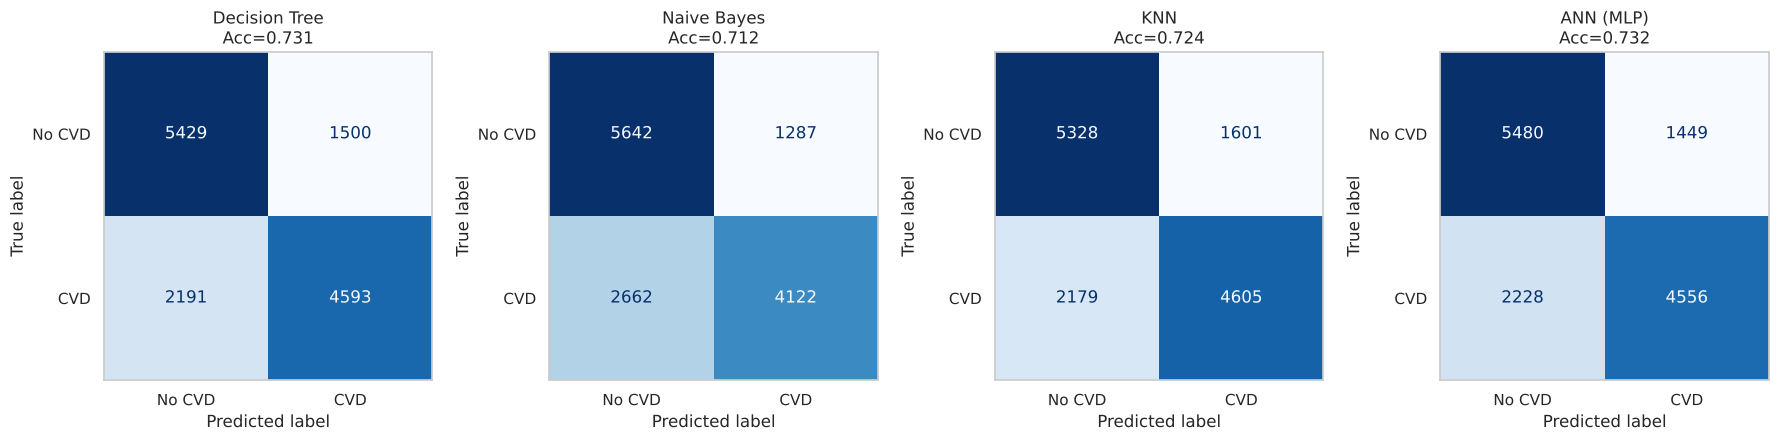

Decision Tree  TP= 4593 TN= 5429 FP= 1500 FN= 2191 | Specificity=0.784 | Miss-rate (FN rate)=0.323
Naive Bayes    TP= 4122 TN= 5642 FP= 1287 FN= 2662 | Specificity=0.814 | Miss-rate (FN rate)=0.392
KNN            TP= 4605 TN= 5328 FP= 1601 FN= 2179 | Specificity=0.769 | Miss-rate (FN rate)=0.321
ANN (MLP)      TP= 4556 TN= 5480 FP= 1449 FN= 2228 | Specificity=0.791 | Miss-rate (FN rate)=0.328


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=['No CVD','CVD']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name}\nAcc={accuracy_score(y_test,p):.3f}'); ax.grid(False)
plt.tight_layout(); plt.show()

for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f'{name:<14} TP={tp:>5} TN={tn:>5} FP={fp:>5} FN={fn:>5} | Specificity={tn/(tn+fp):.3f} | Miss-rate (FN rate)={fn/(fn+tp):.3f}')

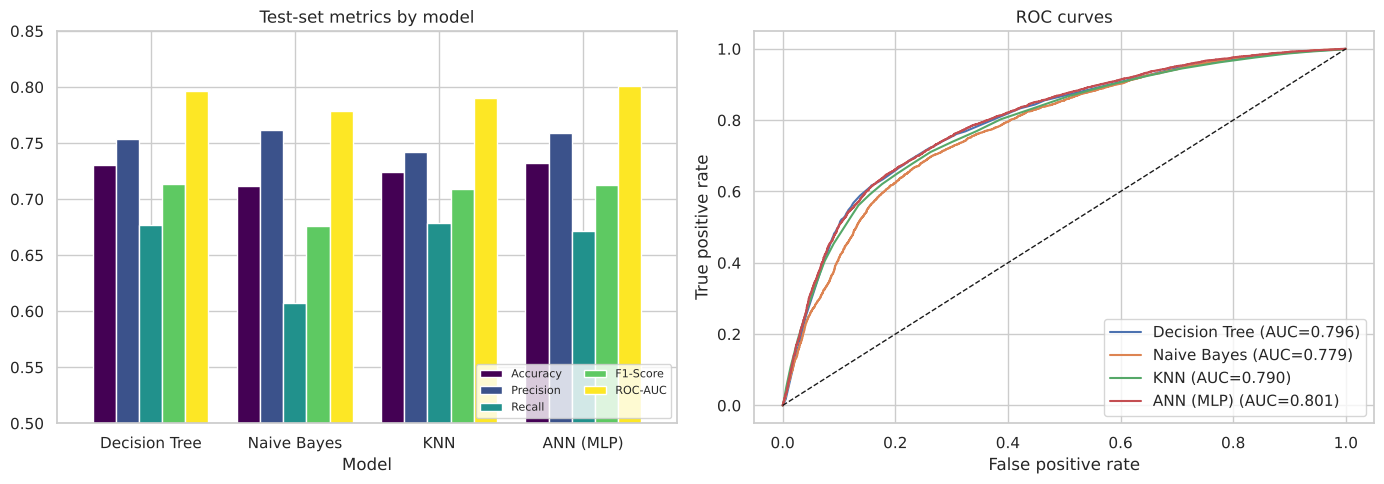

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
res[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']].plot(kind='bar', ax=ax[0], rot=0, colormap='viridis', width=0.8)
ax[0].set_ylim(0.5, 0.85); ax[0].set_title('Test-set metrics by model'); ax[0].legend(loc='lower right', ncol=2, fontsize=8)
for name, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr); ax[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, pr):.3f})')
ax[1].plot([0,1],[0,1],'k--', lw=1); ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate')
ax[1].set_title('ROC curves'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

**Test-set results (13,713 unseen patients).**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Decision Tree | 0.731 | 0.754 | 0.677 | **0.713** | 0.797 |
| Naive Bayes | 0.712 | 0.762 | 0.608 | 0.676 | 0.779 |
| KNN | 0.724 | 0.742 | 0.679 | 0.709 | 0.790 |
| ANN (MLP) | **0.732** | 0.759 | 0.672 | 0.713 | **0.801** |

* **Decision Tree and ANN are statistically indistinguishable on the test set** (F1 0.713 vs 0.713); ANN edges ahead on accuracy, ROC-AUC and cross-validated F1, so it is selected as "best", but the tree is a close second and far more interpretable.
* **All four models plateau at ~72–73 % accuracy.** Very different algorithms reaching the same ceiling suggests the limit lies in the *data* (features available, measurement noise), not in the model choice.
* **Error profile:** every model misses roughly one-third of true CVD cases (false-negative rate 32–39 %). Naive Bayes is the most conservative (highest specificity 0.81, but misses 39 % of cases). KNN and the tree catch the most cases (miss rate ≈ 32 %) at the cost of more false alarms.
* **Speed:** KNN is cheap to train but slow at prediction (≈5 s for 13.7k patients, because it scans all training data), whereas the tree, Naive Bayes and ANN predict in milliseconds.

## 7. Feature importance and interpretation
Two complementary views:
1. **Decision-tree importance** (mean impurity decrease) – model-specific.
2. **Permutation importance** (drop in test F1 when a feature is shuffled) – model-agnostic, so it works for all four models and allows direct comparison.

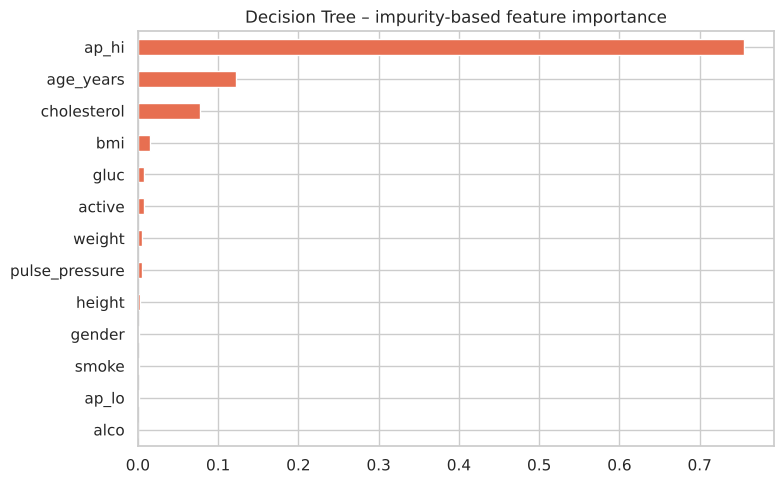

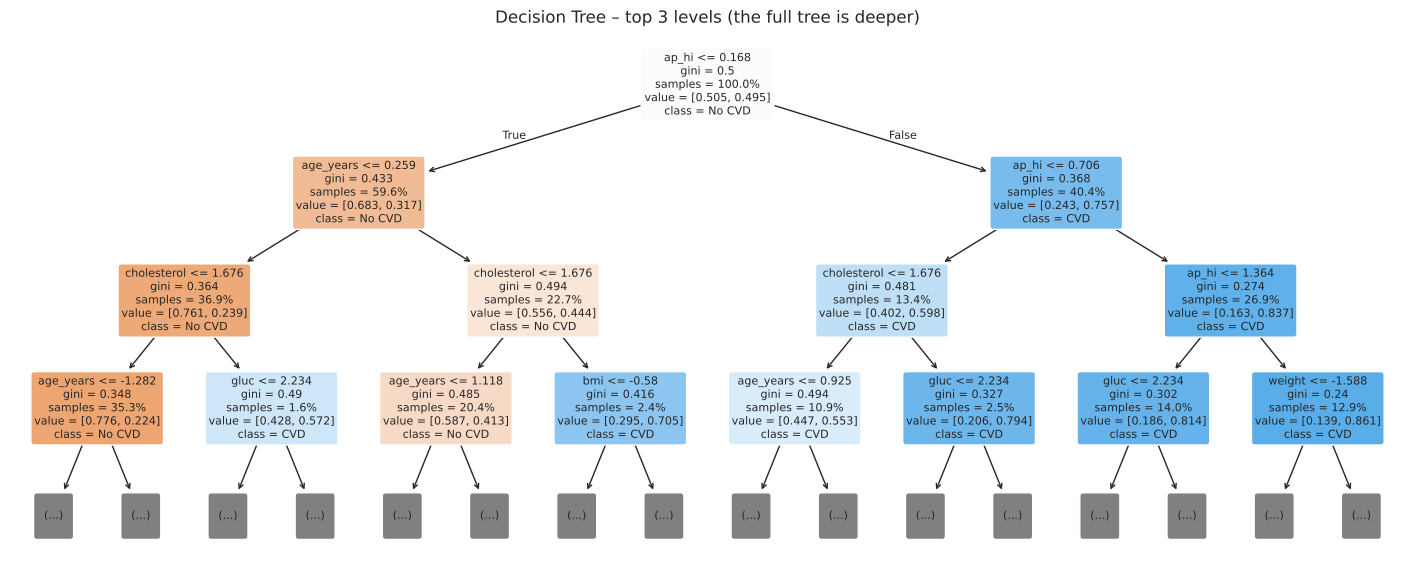

In [13]:
dt = best['Decision Tree'].named_steps['clf']
imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(8, 5)); imp.plot(kind='barh', color='#e76f51'); plt.title('Decision Tree – impurity-based feature importance'); plt.tight_layout(); plt.show()

plt.figure(figsize=(18, 7))
plot_tree(dt, max_depth=3, feature_names=FEATURES, class_names=['No CVD','CVD'], filled=True, rounded=True, fontsize=8, proportion=True)
plt.title('Decision Tree – top 3 levels (the full tree is deeper)'); plt.show()

,Decision Tree,Naive Bayes,KNN,ANN (MLP)
ap_hi,0.164300,0.034100,0.034800,0.037500
cholesterol,0.027900,0.020400,0.025700,0.023900
ap_lo,0.000000,0.020200,0.035600,0.023500
age_years,0.028600,0.003600,0.018300,0.017600
pulse_pressure,-0.001700,0.020100,0.022100,0.014400
active,0.001000,-0.000100,0.000800,0.002900
bmi,0.001600,0.001200,0.000500,-0.000400
gender,0.001000,0.000200,0.001200,0.000100
alco,0.000000,-0.000600,0.001500,0.000700
height,-0.000000,0.000700,0.001600,-0.000900


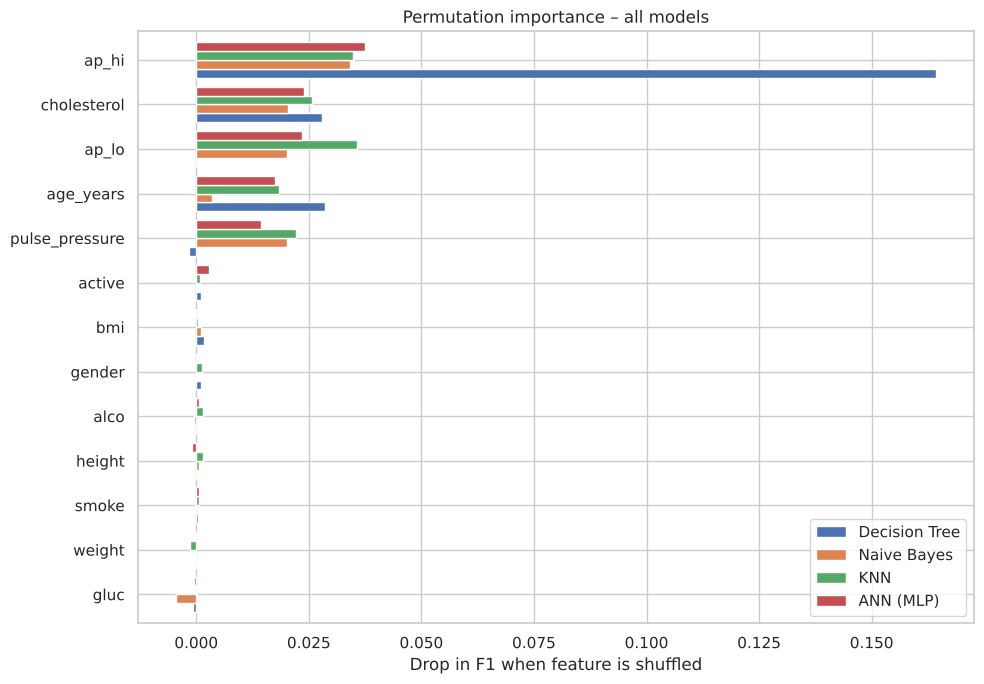

In [14]:
perm = {}
for name, est in best.items():
    r = permutation_importance(est, X_test, y_test, scoring='f1', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm)
order = perm.mean(axis=1).sort_values(ascending=False).index
perm = perm.loc[order]
display(perm.round(4).style.background_gradient(cmap='Reds', axis=None))

perm.iloc[::-1].plot(kind='barh', figsize=(10, 7), width=0.8)
plt.xlabel('Drop in F1 when feature is shuffled'); plt.title('Permutation importance – all models'); plt.tight_layout(); plt.show()

**Interpretation.**
* **Systolic BP is by far the most influential feature.** It accounts for 75 % of the tree's impurity importance, and shuffling it costs the tree 0.164 F1 (about six times any other feature). It is also the top feature for all four models under permutation importance.
* **Cholesterol, age and the diastolic/pulse-pressure pair come next.** Cholesterol is consistently second; age matters to the tree, KNN and ANN. The tree gives diastolic BP ≈ 0 importance because it is redundant with systolic BP once the tree has split on it, whereas Naive Bayes, KNN and ANN spread credit across systolic, diastolic and pulse pressure. This is the usual behaviour of correlated features.
* **BMI, weight, height, gender, glucose, smoking, alcohol and activity contribute almost nothing** to predictions once blood pressure, age and cholesterol are known (importance ≈ 0, some slightly negative = noise).
* The ablation below shows the engineered features (BMI, pulse pressure) did **not** improve test F1 (differences ≤ 0.005), so the models already extract what they need from the raw measurements.
* Importance describes *association in this dataset*, not causation.

### Does adding dedicated feature engineering help?
Quick ablation: re-train the tuned decision tree and ANN without the engineered features (`bmi`, `pulse_pressure`) to see whether they add value beyond the raw measurements.

In [15]:
raw_feats = [f for f in FEATURES if f not in ('bmi','pulse_pressure')]
from sklearn.base import clone
abl=[]
for name in ['Decision Tree','ANN (MLP)']:
    for label, feats in [('with engineered', FEATURES), ('raw only', raw_feats)]:
        m = clone(best[name]).fit(X_train[feats], y_train)
        abl.append({'Model':name,'Feature set':label,'Test F1':round(f1_score(y_test, m.predict(X_test[feats])),4),
                    'Test Acc':round(accuracy_score(y_test, m.predict(X_test[feats])),4)})
display(pd.DataFrame(abl))

,Model,Feature set,Test F1,Test Acc
0,Decision Tree,with engineered,0.7134,0.7308
1,Decision Tree,raw only,0.7119,0.7315
2,ANN (MLP),with engineered,0.7125,0.7319
3,ANN (MLP),raw only,0.7177,0.7311


## 8. Strengths, weaknesses and limitations

| Technique | Strengths | Weaknesses | Limitations seen in this project |
|---|---|---|---|
| **Decision Tree** | Human-readable rules; no scaling needed; handles mixed feature types; very fast; near-best accuracy here | Unstable (small data changes → different tree); overfits if deep; axis-aligned splits only | Needed depth/leaf-size tuning; ignores diastolic BP once systolic is used, so importance of correlated features is hidden |
| **Naive Bayes** | Extremely fast; works with little data; probabilistic output | Assumes features are conditionally independent and Gaussian, both violated (BP variables are correlated; many features are binary/ordinal) | Lowest F1 (0.676) and recall (0.61): misses ~39 % of CVD cases; poorly calibrated probabilities |
| **KNN** | No training; simple; non-linear decision boundary | Slow prediction (~5 s on 13.7k rows) and memory-heavy (stores all data); sensitive to scaling and irrelevant features | Noise features (smoking, height…) dilute distances; hard to deploy at scale; no explanation of *why* |
| **ANN (MLP)** | Best CV F1 and ROC-AUC; learns feature interactions; smooth probabilities | Black box; more hyper-parameters; needs scaling; slower training (≈3 s vs 0.1 s) | Gain over a simple tree is marginal (≈0.5 F1 points CV, none on test), so complexity is hard to justify without an explainability layer |

**Overall limitations of the study:** (1) ~73 % accuracy and a ~1/3 miss rate are not adequate for stand-alone clinical screening; (2) lifestyle and lab features are self-reported or coarse (3-level cholesterol/glucose); (3) no ECG, family history, medications, or LDL/HDL values; (4) a single dataset, with no external validation, ages ≈ 30–65 only; (5) data-entry errors required rule-based cleaning, and different rules would change results slightly; (6) the "disease" label's provenance is not documented in the data.

In [16]:
summary = pd.DataFrame({
 'Test F1': res['F1-Score'], 'Recall': res['Recall'], 'Precision': res['Precision'], 'ROC-AUC': res['ROC-AUC'],
 'Train time (s)': res['Train time (s)'], 'Predict time (s)': res['Predict time (s)']})
display(summary)

,Test F1,Recall,Precision,ROC-AUC,Train time (s),Predict time (s)
Model,,,,,,
Decision Tree,0.7134,0.6770,0.7538,0.7965,0.1379,0.0048
Naive Bayes,0.6761,0.6076,0.7621,0.7786,0.0276,0.0041
KNN,0.7090,0.6788,0.7420,0.7901,0.1319,5.0070
ANN (MLP),0.7125,0.6716,0.7587,0.8005,3.4257,0.0096


## 9. Conceptual intelligent healthcare prediction system
The best-performing model (selected on **cross-validated F1 / ROC-AUC**, with recall and interpretability as tie-breakers for a screening use-case) is wrapped into a decision-support prototype.

```
 ┌────────────┐   ┌────────────────┐   ┌──────────────────┐   ┌────────────────┐   ┌──────────────────┐
 │ Data input │──▶│ Validation &   │──▶│ Preprocessing    │──▶│ Best ML model  │──▶│ Risk score +     │
 │ (EHR / form│   │ plausibility   │   │ (BMI, pulse prs, │   │ (probability   │   │ explanation +    │
 │  / devices)│   │ checks         │   │  scaling)        │   │  of CVD)       │   │ clinician review │
 └────────────┘   └────────────────┘   └──────────────────┘   └────────────────┘   └──────────────────┘
                                                                      ▲                      │
                                                                      └── monitoring, retraining, audit log ◀┘
```

In [17]:
# Select best model: highest tuned CV F1 (ties -> ROC-AUC)
cv_f1 = {r['Model']: float(r['f1'].split(' ')[0]) for _, r in cv_table.reset_index().iterrows()}
best_name = max(cv_f1, key=cv_f1.get)
print('Selected model:', best_name, '| CV F1 =', cv_f1[best_name])
final_model = best[best_name]
joblib.dump({'model': final_model, 'features': FEATURES, 'name': best_name}, 'cvd_best_model.joblib')

def predict_patient(age_years, gender, height_cm, weight_kg, ap_hi, ap_lo, cholesterol, gluc, smoke, alco, active, model=final_model):
    """Prototype clinical-decision-support function. gender: 'F' or 'M'; cholesterol/gluc: 1-3; smoke/alco/active: 0/1."""
    # 1. validation layer
    if not (70 <= ap_hi <= 250 and 40 <= ap_lo <= 150 and ap_hi > ap_lo): raise ValueError('Implausible blood-pressure values – please re-measure.')
    if not (120 <= height_cm <= 220 and 30 <= weight_kg <= 200): raise ValueError('Implausible height/weight.')
    # 2. preprocessing layer
    row = pd.DataFrame([{ 'age_years':age_years, 'gender':int(gender=='M'), 'height':height_cm, 'weight':weight_kg,
        'bmi':weight_kg/(height_cm/100)**2, 'ap_hi':ap_hi, 'ap_lo':ap_lo, 'pulse_pressure':ap_hi-ap_lo,
        'cholesterol':cholesterol, 'gluc':gluc, 'smoke':smoke, 'alco':alco, 'active':active}])[FEATURES]
    # 3. model layer
    p = float(model.predict_proba(row)[0,1])
    # 4. decision layer (tiers are illustrative – thresholds must be set with clinicians)
    tier = 'LOW' if p < 0.35 else 'MODERATE' if p < 0.65 else 'HIGH'
    return {'probability_cvd': round(p,3), 'risk_tier': tier,
            'advice': {'LOW':'Routine check-up / lifestyle advice.','MODERATE':'Follow-up BP & lipid screening within 3 months.','HIGH':'Refer for clinical assessment.'}[tier]}

print(predict_patient(45,'M',175,82,125,80,1,1,0,0,1))
print(predict_patient(62,'F',160,88,165,100,3,2,0,0,0))

Selected model: ANN (MLP) | CV F1 = 0.7214
{'probability_cvd': 0.25, 'risk_tier': 'LOW', 'advice': 'Routine check-up / lifestyle advice.'}
{'probability_cvd': 0.793, 'risk_tier': 'HIGH', 'advice': 'Refer for clinical assessment.'}


**Design choices.** ANN was selected by cross-validated F1 (0.7214) with ROC-AUC as tie-breaker. In a real deployment you would weigh this against the Decision Tree, which is almost as accurate and can be explained to clinicians as rules. A reasonable design is to *serve the ANN's probability while displaying tree-based or permutation-based explanations*. Key governance points: (a) the tool is **decision support, not diagnosis**: a clinician reviews every HIGH/MODERATE result; (b) choose the alert threshold to favour **recall** because a missed case costs more than a false alarm; (c) data validation at input (the same plausibility rules as training); (d) audit logs, consent and de-identification; (e) drift monitoring and scheduled retraining; (f) prospective, external validation before any clinical use. The accompanying Streamlit app (`app.py`) implements this prototype.

## 10. Conclusion


* **Best model:** the **ANN (MLP)** by cross-validated F1 (0.721) and ROC-AUC (0.80), but its advantage over the **Decision Tree** is small and not visible on the test F1 (both 0.713).
* **Practical recommendation:** use the tree if interpretability matters, the ANN if the last bit of discrimination matters. **Avoid Naive Bayes** (weakest recall) and **KNN** for deployment (slow, no explanations, no accuracy advantage).
* **Key risk factors:** systolic blood pressure ≫ cholesterol > diastolic BP / pulse pressure ≈ age; lifestyle flags and BMI add little.
* **Main takeaway:** all four algorithms converge on ≈72–73 % accuracy, so **better data (more clinical features, validated labels) would help more than a fancier model**.

---
*Reproducibility: all random seeds fixed (`RANDOM_STATE = 42`). Requirements: `pandas numpy scikit-learn matplotlib seaborn joblib`.*